**Load and Prepare the Diabetes Dataset**

In [1]:
import pandas as pd
import numpy as np

# Load the dataset (update filename if needed)
df = pd.read_csv('/content/diabetesN.csv')
X_num = df.drop(columns=['Outcome'])
y_true = df['Outcome']

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**Standard K-Means (Scaled Numerical)**

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

kmeans_std = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_std = kmeans_std.fit_predict(X_scaled)

**Convert Tabular Records to Text**

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

def record_to_text(row):
    return (
        f"Patient record: pregnancies {int(row['Pregnancies'])}, "
        f"glucose level {row['Glucose']} mg/dL, "
        f"blood pressure {row['BloodPressure']} mmHg, "
        f"skin thickness {row['SkinThickness']} mm, "
        f"insulin level {row['Insulin']} mu U/ml, "
        f"body mass index {row['BMI']} kg/m2, "
        f"diabetes pedigree function {row['DiabetesPedigreeFunction']}, "
        f"age {int(row['Age'])} years."
    )

texts = df.apply(record_to_text, axis=1).tolist()

tfidf = TfidfVectorizer(stop_words='english')
X_tfidf = tfidf.fit_transform(texts).toarray()

kmeans_tfidf = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_tfidf = kmeans_tfidf.fit_predict(X_tfidf)

**Pretrained BERT Embeddings + K-Means**

In [4]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
bert_model = AutoModel.from_pretrained(model_name).to(device)
bert_model.eval()

def get_bert_embeddings(text_list, batch_size=32):
    all_embeddings = []
    for i in range(0, len(text_list), batch_size):
        batch = text_list[i:i + batch_size]
        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors='pt'
        ).to(device)

        with torch.no_grad():
            outputs = bert_model(**encoded)
            mask = encoded['attention_mask'].unsqueeze(-1).expand(outputs.last_hidden_state.size()).float()
            sum_embeddings = torch.sum(outputs.last_hidden_state * mask, dim=1)
            sum_mask = torch.clamp(mask.sum(dim=1), min=1e-9)
            mean_pooled = (sum_embeddings / sum_mask).cpu().numpy()
            all_embeddings.append(mean_pooled)

    return np.vstack(all_embeddings)

X_bert = get_bert_embeddings(texts)

kmeans_bert = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_bert = kmeans_bert.fit_predict(X_bert)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


**Evaluation & Comparison Table**

In [5]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

def evaluate_clustering(X, labels, y_true):
    return {
        "Silhouette Score": round(silhouette_score(X, labels), 4),
        "Davies-Bouldin Index": round(davies_bouldin_score(X, labels), 4),
        "Calinski-Harabasz Index": round(calinski_harabasz_score(X, labels), 2),
        "Adjusted Rand Index (ARI)": round(adjusted_rand_score(y_true, labels), 4),
        "Normalized Mutual Info (NMI)": round(normalized_mutual_info_score(y_true, labels), 4)
    }

metrics_df = pd.DataFrame([
    evaluate_clustering(X_scaled, labels_std, y_true),
    evaluate_clustering(X_tfidf, labels_tfidf, y_true),
    evaluate_clustering(X_bert, labels_bert, y_true)
], index=[
    "Standard K-Means (Scaled Numerical)",
    "TF-IDF Vectorization + K-Means",
    "BERT Embeddings (Pretrained) + K-Means"
])

metrics_df

,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Adjusted Rand Index (ARI),Normalized Mutual Info (NMI)
Standard K-Means (Scaled Numerical),0.1960,2.0118,151.620000,0.1137,0.0617
TF-IDF Vectorization + K-Means,0.0070,6.2722,8.520000,0.0365,0.0106
BERT Embeddings (Pretrained) + K-Means,0.2892,1.3377,399.630005,0.0016,0.0005


**PCA Cluster Visualization**

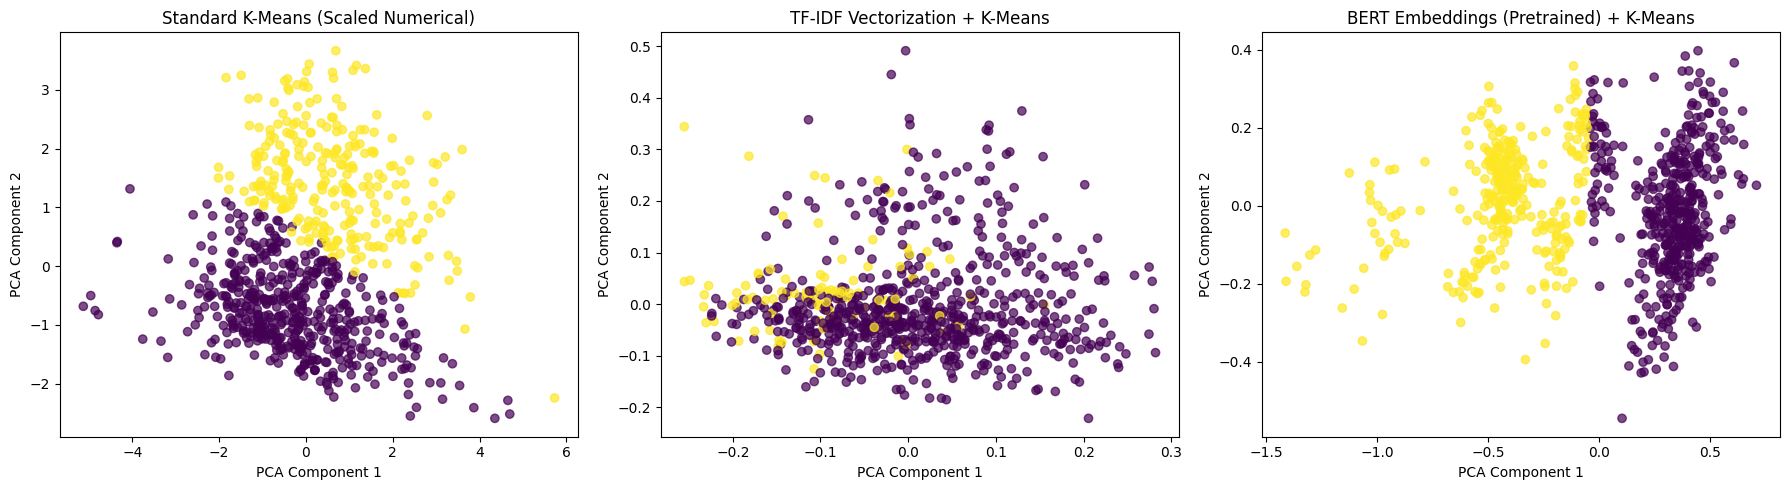

In [6]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def align_labels(y_true, cluster_labels):
    if adjusted_rand_score(y_true, cluster_labels) >= 0:
        if np.mean(y_true[cluster_labels == 1]) < np.mean(y_true[cluster_labels == 0]):
            return 1 - cluster_labels
    return cluster_labels

labels_std_aligned = align_labels(y_true, labels_std)
labels_tfidf_aligned = align_labels(y_true, labels_tfidf)
labels_bert_aligned = align_labels(y_true, labels_bert)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

methods = [
    (X_scaled, labels_std_aligned, "Standard K-Means (Scaled Numerical)"),
    (X_tfidf, labels_tfidf_aligned, "TF-IDF Vectorization + K-Means"),
    (X_bert, labels_bert_aligned, "BERT Embeddings (Pretrained) + K-Means")
]

for ax, (data, lbls, title) in zip(axes, methods):
    pca_2d = PCA(n_components=2, random_state=42).fit_transform(data)
    ax.scatter(pca_2d[:, 0], pca_2d[:, 1], c=lbls, cmap='viridis', alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")

plt.tight_layout()
plt.savefig("kmeans_diabetes_comparison.png", dpi=300)
plt.show()